In [1]:
import sys
from pathlib import Path


sys.path.insert(0, str(Path.cwd().parent))

from cartera.db import conectar
from cartera.valoracion import rentabilidades_totales, rentabilidad_twr
from cartera.riesgo import tabla_riesgo

conn = conectar()

In [2]:
cartera_id_demo = conn.execute("SELECT id FROM carteras WHERE nombre = 'Demo';").fetchone()[0]
cartera_id_demo

1

In [3]:
activos = rentabilidades_totales(conn, ["BBVA.MC", "JPM", "KO", "REP.MC", "TEF.MC"])
benchmark = rentabilidades_totales(conn, ["URTH"])["URTH"]
cartera = rentabilidad_twr(conn, cartera_id_demo)

todo = activos.assign(Cartera=cartera, URTH=benchmark)
tabla_riesgo(todo, benchmark).round(3)

,rent_anual,vol_anual,sharpe,sortino,max_drawdown,beta,correlacion,tracking_error,ratio_informacion
BBVA.MC,0.415,0.300,1.243,1.783,-0.308,0.549,0.334,0.296,1.015
JPM,0.168,0.252,0.666,0.954,-0.283,0.921,0.663,0.191,0.428
KO,0.153,0.184,0.758,1.099,-0.205,0.388,0.382,0.205,0.258
REP.MC,0.282,0.280,0.957,1.350,-0.363,0.161,0.105,0.319,0.613
TEF.MC,0.036,0.212,0.181,0.245,-0.338,0.064,0.055,0.275,-0.182
Cartera,0.380,0.145,2.161,3.236,-0.059,0.377,0.420,0.168,1.203
URTH,0.101,0.183,0.506,0.732,-0.207,1.000,1.000,0.000,NaN


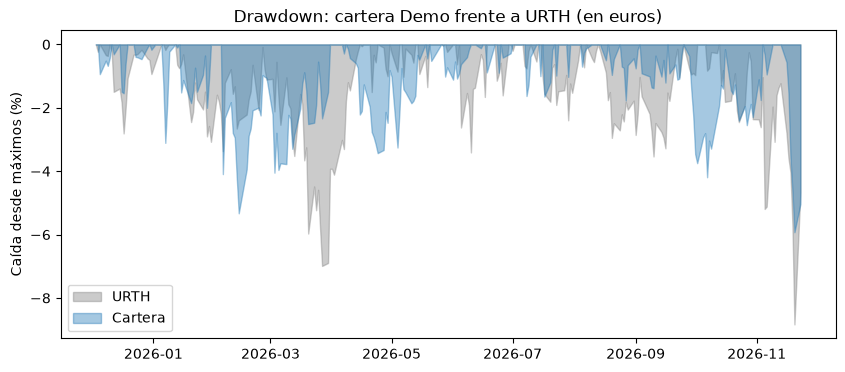

In [4]:
import matplotlib.pyplot as plt
from pathlib import Path
from cartera.riesgo import alinear, drawdowns, volatilidad_ewma

CARPETA = Path.cwd().parent / "graficos"
CARPETA.mkdir(exist_ok=True)

a = alinear(cartera, benchmark)
a.columns = ["Cartera", "URTH"]

fig, ax = plt.subplots(figsize=(10, 4))
for nombre, color in [("URTH", "tab:gray"), ("Cartera", "tab:blue")]:
    dd = drawdowns(a[nombre]) * 100
    ax.fill_between(dd.index, dd, 0, color=color, alpha=0.4, label=nombre)
ax.set_ylabel("Caída desde máximos (%)")
ax.set_title("Drawdown: cartera Demo frente a URTH (en euros)")
ax.legend(loc="lower left")
fig.savefig(CARPETA / "drawdown.png", dpi=150, bbox_inches="tight")

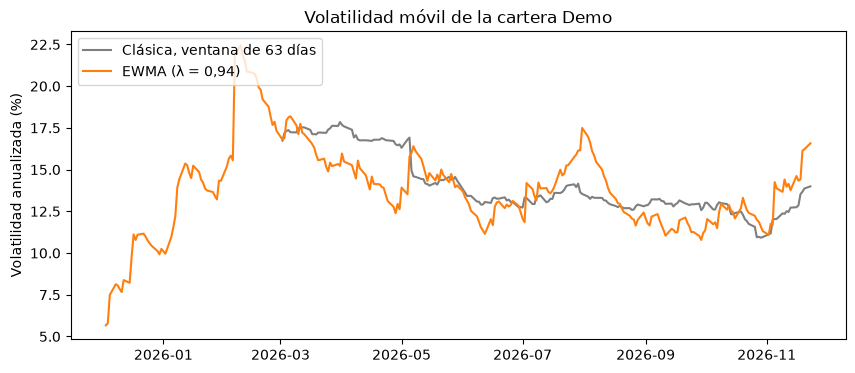

In [5]:
import numpy as np
r = cartera.dropna()
vol_ewma = volatilidad_ewma(r) * 100
vol_63 = r.rolling(63).std() * np.sqrt(252) * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(vol_63.index, vol_63, label="Clásica, ventana de 63 días", color="tab:gray")
ax.plot(vol_ewma.index, vol_ewma, label="EWMA (λ = 0,94)", color="tab:orange")
ax.set_ylabel("Volatilidad anualizada (%)")
ax.set_title("Volatilidad móvil de la cartera Demo")
ax.legend(loc="upper left")
fig.savefig(CARPETA / "volatilidad.png", dpi=150, bbox_inches="tight")

In [6]:
import pandas as pd
from scipy import stats
from cartera.riesgo import tabla_var_cvar

pd.set_option("display.width", 200)

for nivel in [0.95, 0.99]:
    t = tabla_var_cvar(todo, nivel)
    t.iloc[:, :6] = t.iloc[:, :6] * 100
    print(f"\nVaR y CVaR diarios al {nivel:.0%} (en %)")
    display(t.round(2))


VaR y CVaR diarios al 95% (en %)


,var_historico,var_normal,var_t,cvar_historico,cvar_normal,cvar_t,grados_libertad
BBVA.MC,2.91,2.95,2.71,4.42,3.74,4.16,4.07
JPM,2.58,2.53,2.33,3.66,3.19,3.55,4.06
KO,1.78,1.84,1.75,2.51,2.33,2.53,5.08
REP.MC,2.69,2.79,2.60,4.20,3.53,3.87,4.61
TEF.MC,1.95,2.17,1.99,3.11,2.73,2.87,5.06
Cartera,1.32,1.37,1.34,1.88,1.75,1.77,18.45
URTH,1.76,1.85,1.73,2.57,2.34,2.58,4.30



VaR y CVaR diarios al 99% (en %)


,var_historico,var_normal,var_t,cvar_historico,cvar_normal,cvar_t,grados_libertad
BBVA.MC,5.11,4.24,4.90,7.40,4.88,6.87,4.07
JPM,4.44,3.61,4.17,5.54,4.15,5.83,4.06
KO,2.72,2.63,2.96,4.03,3.03,3.92,5.08
REP.MC,5.37,3.99,4.54,6.39,4.59,6.17,4.61
TEF.MC,3.81,3.08,3.35,5.59,3.54,4.44,5.06
Cartera,1.98,1.99,2.04,2.81,2.30,2.43,18.45
URTH,3.07,2.64,3.02,4.11,3.03,4.15,4.30


In [7]:
from cartera.valoracion import resumen_cartera
from cartera.riesgo import var_historico, cvar_historico, var_tStudent, cvar_tStudent

nivel = 0.99
r_cartera = cartera.dropna()
valor = resumen_cartera(conn, cartera_id_demo)["valor_actual"]

var_eur = var_historico(r_cartera, nivel) * valor
cvar_eur = cvar_historico(r_cartera, nivel) * valor
var_t_eur = var_tStudent(r_cartera, nivel) * valor

print(f"Valor actual de la cartera: {valor:,.0f} €")
print(f"Con un {nivel:.0%} de confianza, mañana no perderás más de {var_eur:,.0f} € (histórico).")
print(f"Con la t de Student: {var_t_eur:,.0f} €.")
print(f"Y si ocurre ese 1 % de días malos, la pérdida media sería de {cvar_eur:,.0f} €.")

Valor actual de la cartera: 20,380 €
Con un 99% de confianza, mañana no perderás más de 403 € (histórico).
Con la t de Student: 415 €.
Y si ocurre ese 1 % de días malos, la pérdida media sería de 572 €.


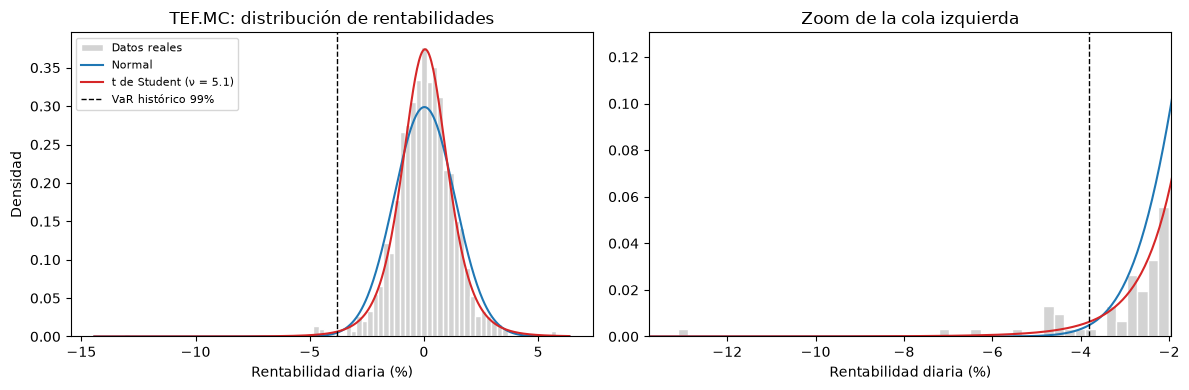

In [8]:
from scipy import stats

nombre = "TEF.MC"
r = todo[nombre].dropna()

mu, sigma = r.mean(), r.std()
df, loc, escala = stats.t.fit(r)
x = np.linspace(r.min() * 1.1, r.max() * 1.1, 500)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for ax in (ax1, ax2):
    ax.hist(r * 100, bins=80, density=True, color="lightgray", edgecolor="white", label="Datos reales")
    ax.plot(x * 100, stats.norm.pdf(x, mu, sigma) / 100, color="tab:blue", label="Normal")
    ax.plot(x * 100, stats.t.pdf(x, df, loc, escala) / 100, color="tab:red", label=f"t de Student (ν = {df:.1f})")
    ax.axvline(-var_historico(r, nivel) * 100, color="black", ls="--", lw=1, label=f"VaR histórico {nivel:.0%}")
    ax.set_xlabel("Rentabilidad diaria (%)")

ax1.set_title(f"{nombre}: distribución de rentabilidades")
ax1.set_ylabel("Densidad")
ax1.legend(fontsize=8)

corte = r.quantile(0.05)
ax2.set_xlim(r.min() * 100 * 1.05, corte * 100)
ax2.set_ylim(0, stats.norm.pdf(corte, mu, sigma) / 100 * 1.3)
ax2.set_title("Zoom de la cola izquierda")

fig.tight_layout()
fig.savefig(CARPETA / f"colas_{nombre}.png", dpi=150, bbox_inches="tight")

In [9]:
import matplotlib.pyplot as plt
from cartera.riesgo import backtest_var, tabla_backtest


def grafico_backtest(r, nombre, metodo="historico", ventana=250, ax=None):
    d = backtest_var(r.dropna(), 0.99, ventana, metodo)
    exc = d[d["excepcion"]]
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(d.index, d["r"] * 100, width=1, color="lightgray", label="Rentabilidad diaria")
    ax.plot(d.index, -d["var"] * 100, color="black", lw=1, label="VaR 99 % previsto")
    ax.scatter(exc.index, exc["r"] * 100, color="red", s=12, zorder=3, label=f"Excepciones ({len(exc)})")
    ax.set_title(f"{nombre}: backtest del VaR 99 % ({metodo})")
    ax.set_ylabel("%")
    ax.legend(loc="lower left", fontsize=8)
    return ax

In [10]:
activos_y_urth = activos.assign(URTH=benchmark)
tabla_backtest(activos_y_urth)

dias excepciones esperadas  p_kupiec exc_ultimos_250     color
BBVA.MC historico  1040          12      10.4  0.626448             3.0     verde
        ewma       1289          26     12.89   0.00126             5.0  amarillo
JPM     historico  1040          14      10.4  0.286574             2.0     verde
        ewma       1289          31     12.89  0.000017             6.0  amarillo
KO      historico  1040          10      10.4  0.900157             4.0     verde
        ewma       1289          23     12.89   0.01081             2.0     verde
REP.MC  historico  1040          14      10.4  0.286574             7.0  amarillo
        ewma       1289          23     12.89   0.01081             4.0     verde
TEF.MC  historico  1040          15      10.4  0.178759             3.0     verde
        ewma       1289          25     12.89  0.002676             4.0     verde
URTH    historico  1003          18     10.03  0.022893             4.0     verde
        ewma       1252          23     12.52  0.007689             6.0  amarillo

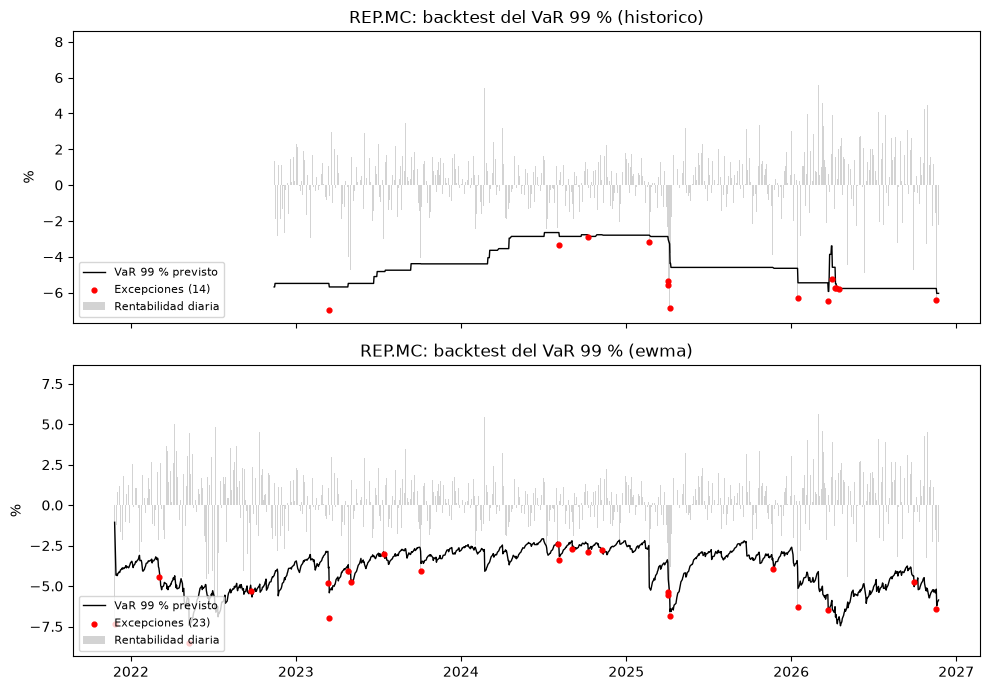

In [11]:
nombre = "REP.MC"

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
grafico_backtest(activos_y_urth[nombre], nombre, "historico", ax=axes[0])
grafico_backtest(activos_y_urth[nombre], nombre, "ewma", ax=axes[1])
fig.tight_layout()
fig.savefig(CARPETA / f"backtest_{nombre}.png", dpi=150, bbox_inches="tight")

In [12]:
from cartera.simulacion import simular_cartera, valores_actuales_eur
from cartera.valoracion import rentabilidades_totales
from cartera.riesgo import var_normal

valores = valores_actuales_eur(conn, cartera_id_demo)
V0 = valores.sum()

r = rentabilidades_totales(conn, list(valores.index))
r = r[r.index >= r.index.max() - pd.DateOffset(years=5)].dropna()
log_r = np.log1p(r)
log_r.describe()
print(type(log_r), log_r.shape)

<class 'pandas.DataFrame'> (1290, 5)


In [13]:
finales = simular_cartera(valores,log_r, dias=252, n=10_000, semilla=42)
perd = V0 - finales

In [14]:
filas = {}
for nivel in (0.95, 0.99):
    var = np.percentile(perd, nivel*100)
    filas[f"{nivel:.0%}"] = {"VaR (€)": var, "CVaR (€)": perd[perd >= var].mean()}
tabla = pd.DataFrame(filas).T

print(f"Valor actual: {V0:,.0f} €")
print(f"Pérdida esperada: {perd.mean():,.0f} €")
print(f"P(perder > 10 %): {(finales < 0.9*V0).mean():.1%}")
tabla.round(0)

Valor actual: 20,380 €
Pérdida esperada: -2,731 €
P(perder > 10 %): 1.4%


,VaR (€),CVaR (€)
95%,1044.0,1786.0
99%,2272.0,2896.0


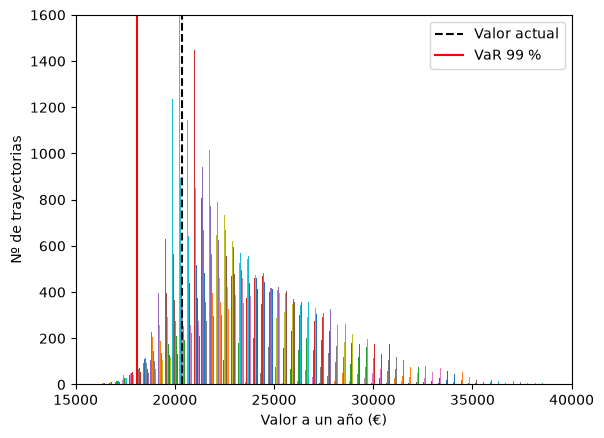

In [15]:
plt.hist(finales, bins=100)
plt.axvline(V0, color="k", ls="--", label="Valor actual")
plt.axvline(V0 - tabla.loc["99%", "VaR (€)"], color="r", label="VaR 99 %")
plt.ylim(0, 1600)
plt.xlim(15_000,40_000)
plt.xlabel("Valor a un año (€)")
plt.ylabel("Nº de trayectorias")
plt.legend()
plt.show()

In [16]:
fin_1d = simular_cartera(valores,log_r, dias=1, n=100_000, semilla=42)
perd_1d = V0 - fin_1d

w = valores / V0
r_cart = (r[valores.index] * w).sum(axis=1)

comp = pd.DataFrame({
    "Monte Carlo": [np.percentile(perd_1d, 95), np.percentile(perd_1d, 99)],
    "Normal": [var_normal(r_cart, 0.95) * V0, var_normal(r_cart, 0.99) * V0],
}, index=["95%", "99%"])
comp.round(0)

,Monte Carlo,Normal
95%,230.0,298.0
99%,379.0,430.0


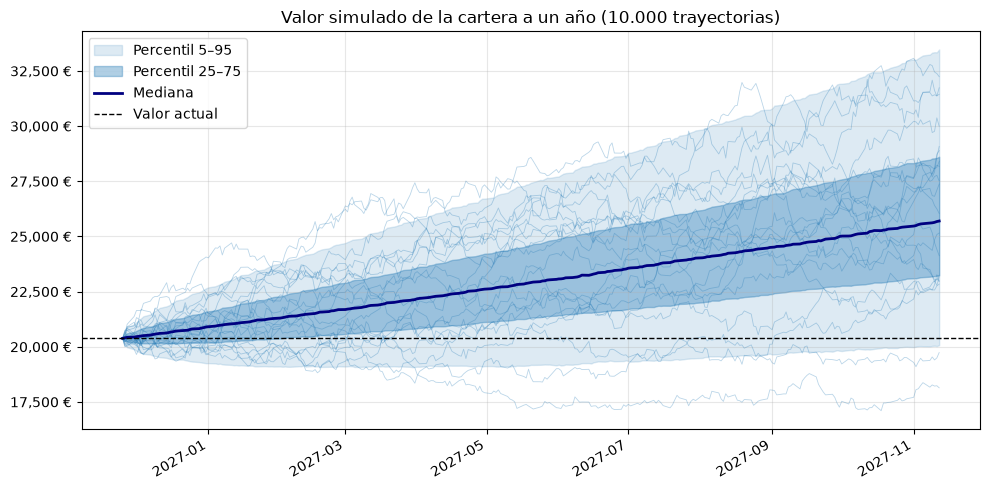

In [17]:
import matplotlib.ticker as mticker
from cartera.simulacion import trayectorias_cartera

V = trayectorias_cartera(log_r, valores, dias=252, n=10_000, semilla=42)
fechas = pd.bdate_range(pd.Timestamp.today().normalize(), periods=V.shape[1])
percentiles = [5, 25, 50, 75, 95]
bandas = np.percentile(V, percentiles, axis=0)
idx = np.random.default_rng(0).choice(len(V), 20, replace=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(fechas, bandas[0], bandas[4], color="tab:blue", alpha=0.15, label="Percentil 5–95")
ax.fill_between(fechas, bandas[1], bandas[3], color="tab:blue", alpha=0.35, label="Percentil 25–75")
ax.plot(fechas, V[idx].T, color="tab:blue", lw=0.6, alpha=0.3)
ax.plot(fechas, bandas[2], color="navy", lw=2, label="Mediana")
ax.axhline(V0, color="k", ls="--", lw=1, label="Valor actual")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f} €"))
ax.set_title("Valor simulado de la cartera a un año (10.000 trayectorias)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(CARPETA / "fan_chart.png", dpi=150)
plt.show()